# Notebook 3 – Data Quality Assessment




## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.DataFrame({
    "employee_id": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012],
    "age": [22, 25, 29, 31, 35, 41, 27, 38, 45, 24, np.nan, 31],
    "department": ["IT", "HR", "IT", "Sales", "IT", "Finance", "Sales", "HR", "Finance", "IT", "Sales", "it "],
    "education": ["Bachelor", "Master", "Bachelor", "Bachelor", "Master", "PhD", "Bachelor", "Master", "Bachelor", "Bachelor", "Master", "Bachelor"],
    "monthly_salary": [28000, 35000, 45000, 42000, 65000, 82000, 39000, 56000, 90000, 32000, 47000, 45000],
    "monthly_spending": [12000, 16000, 20000, 19000, 25000, 30000, 18000, 24000, 32000, 15000, 21000, 20000],
    "remote": ["No", "Yes", "Yes", "No", "Yes", "Yes", "No", "Yes", "No", "No", "Yes", "Yes"],
    "joined_date": pd.to_datetime(["2022-01-10", "2021-05-15", "2020-03-01", "2023-02-20", "2018-07-12", "2016-11-30", "2022-09-05", "2019-04-18", "2014-08-25", "2023-06-01", "2020-12-14", "2021-08-09"]),
    "left_company": ["No", "No", "No", "Yes", "No", "No", "Yes", "No", "No", "No", "Yes", "No"]
})
df


,employee_id,age,department,education,monthly_salary,monthly_spending,remote,joined_date,left_company
0,1001,22.0,IT,Bachelor,28000,12000,No,2022-01-10,No
1,1002,25.0,HR,Master,35000,16000,Yes,2021-05-15,No
2,1003,29.0,IT,Bachelor,45000,20000,Yes,2020-03-01,No
3,1004,31.0,Sales,Bachelor,42000,19000,No,2023-02-20,Yes
4,1005,35.0,IT,Master,65000,25000,Yes,2018-07-12,No
5,1006,41.0,Finance,PhD,82000,30000,Yes,2016-11-30,No
6,1007,27.0,Sales,Bachelor,39000,18000,No,2022-09-05,Yes
7,1008,38.0,HR,Master,56000,24000,Yes,2019-04-18,No
8,1009,45.0,Finance,Bachelor,90000,32000,No,2014-08-25,No
9,1010,24.0,IT,Bachelor,32000,15000,No,2023-06-01,No


## 2. Missing Values
**Definition:** A missing value means that the value is unknown, unavailable, or not recorded.

**Simple example:** A student record has no mark entered.

**Real-world example:** A sensor temporarily stops reporting temperature.

**Business example:** A sales record is missing the customer's region.

**AI/ML use case:** Missing numeric values may be imputed with a median; categorical values may use a most-frequent or explicit 'Unknown' category, depending on context.

**Importance:** Missingness can bias summaries and model predictions. Investigate why values are missing before choosing a treatment.

In [2]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing_count, "missing_percent": missing_percent})
display(missing_summary.sort_values("missing_percent", ascending=False))
display(df[df.isna().any(axis=1)])

,missing_count,missing_percent
age,1,8.33
employee_id,0,0.00
department,0,0.00
education,0,0.00
monthly_salary,0,0.00
monthly_spending,0,0.00
remote,0,0.00
joined_date,0,0.00
left_company,0,0.00


,employee_id,age,department,education,monthly_salary,monthly_spending,remote,joined_date,left_company
10,1011,NaN,Sales,Master,47000,21000,Yes,2020-12-14,Yes


### Missing-value patterns
A missingness map shows which rows and columns contain missing values. A pattern can suggest a systematic issue, but it does not prove the cause.

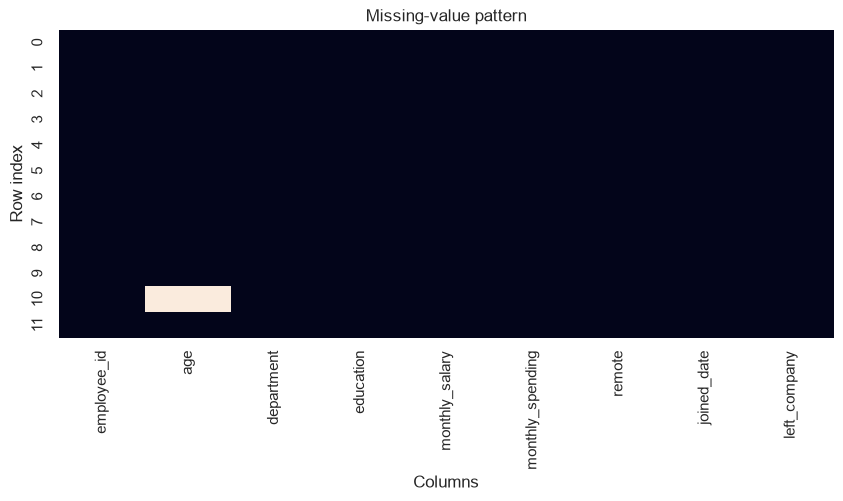

In [3]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing-value pattern")
plt.xlabel("Columns")
plt.ylabel("Row index")
plt.show()

## 3. Duplicate Records
**Definition:** A duplicate is a repeated record. A fully duplicated row matches another row across every column. A potential duplicate may share a business key such as customer ID and date.

**Simple example:** The same invoice is accidentally imported twice.

**Real-world example:** A web form submits the same registration twice.

**Business example:** Duplicate sales can inflate reported revenue.

**AI/ML use case:** Duplicated examples can overweight certain cases and cause train/test leakage if copies appear in both sets.

**Importance:** Check before deleting: two rows with the same customer can be legitimate if they are different purchases.

In [ ]:
print("Fully duplicated rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
print("Duplicate employee IDs:", df["employee_id"].duplicated().sum())
display(df[df.duplicated(subset=["employee_id"], keep=False)])

## 4. Invalid Values
**Definition:** Invalid values violate the rules or meaning of a field.

**Simple example:** A person's age is -5.

**Real-world example:** A device reports a temperature outside its physically possible range.

**Business example:** A product quantity is negative when returns are not represented as negative quantities.

**AI/ML use case:** Invalid values distort feature distributions and can cause unrealistic predictions.

**Importance:** Domain rules are essential; negative revenue might be valid if it represents a refund, so do not assume without context.

In [4]:
print("Negative ages:", (df["age"] < 0).sum())
print("Negative salaries:", (df["monthly_salary"] < 0).sum())
impossible_age = df[(df["age"] < 0) | (df["age"] > 120)]
display(impossible_age)

Negative ages: 0
Negative salaries: 0


,employee_id,age,department,education,monthly_salary,monthly_spending,remote,joined_date,left_company


## 5. Incorrect Categories, Empty Strings, and Null-like Text
**Definition:** Category inconsistency occurs when the same meaning is written in different forms. Empty strings or text such as 'NA' may look missing but are not always recognized as actual null values.

**Simple example:** `IT`, `it`, and `IT ` may mean the same department.

**Business example:** Different spellings of a city split sales reports across several labels.

**AI/ML use case:** Inconsistent labels can create extra encoded features or unseen categories at prediction time.

**Importance:** Normalize only when the values truly have the same meaning; preserve meaningful distinctions.

In [8]:
print(df["department"].value_counts(dropna=False))

object_columns = df.select_dtypes(include=["str"]).columns

for column in object_columns:
    values = df[column].astype("string").str.strip()

    empty_count = values.eq("").fillna(False).sum()

    null_like_count = (
        values.str.lower()
        .isin(["na", "n/a", "null", "none", "nan"])
        .fillna(False)
        .sum()
    )

    print(
        f"{column}: empty strings={empty_count}, "
        f"null-like text={null_like_count}"
    )

department
IT         4
Sales      3
HR         2
Finance    2
it         1
Name: count, dtype: int64
department: empty strings=0, null-like text=0
education: empty strings=0, null-like text=0
remote: empty strings=0, null-like text=0
left_company: empty strings=0, null-like text=0


## 6. Invalid Dates and Incorrect Data Types
**Definition:** A value has an incorrect type when it is stored in a form unsuitable for its meaning; an invalid date cannot be parsed as a real date.

**Simple example:** Storing a date as text can prevent date calculations.

**Business example:** A wrongly parsed date may place an order in the wrong month.

**AI/ML use case:** Correct dates allow useful features such as tenure, month, or day of week.

**Importance:** Type conversion should be checked carefully because ambiguous date formats can be interpreted incorrectly.

In [ ]:
print("joined_date dtype:", df["joined_date"].dtype)
parsed_dates = pd.to_datetime(df["joined_date"], errors="coerce")
print("Unparseable dates:", parsed_dates.isna().sum())
display(df[parsed_dates.isna()])

## 7. Clean a copy (example only)
Cleaning rules depend on the domain. Keep the original data so changes are traceable.

In [ ]:
clean_df = df.copy()
clean_df["department"] = clean_df["department"].astype("string").str.strip().str.title()
clean_df["age"] = clean_df["age"].fillna(clean_df["age"].median())
clean_df = clean_df.drop_duplicates()
print("Missing ages after example fill:", clean_df["age"].isna().sum())
print("Cleaned shape:", clean_df.shape)
display(clean_df.head())

## 8. ML pipeline impact
Data quality checks prevent models from learning from corrupt, duplicated, or inconsistently labeled records. Build cleaning steps into a reproducible pipeline. Fit imputers and transformations on training data only, then apply the fitted steps to validation and test data to avoid data leakage.